В данном ноутубке была реализована кастомная CNN: разработана собственная компактная сверточная архитектура с остаточными блоками и SE-блоками.

Был использован датасет с Kaggle: https://www.kaggle.com/datasets/ozguraslank/brain-stroke-ct-dataset

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

2025-12-03 11:44:52.516222: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764762292.898343      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764762293.002519      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

data_path = "/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset"
test_path = os.path.join(data_path, "External_Test")

img_size = (320, 320)
batch_size = 16
AUTOTUNE = tf.data.AUTOTUNE

class_map = {"Bleeding": 1, "Ischemia": 2, "Normal": 0}
num_class = 3
class_names = ["Normal", "Bleeding", "Ischemia"]

In [ ]:
def safe_decode_png(path):
    img_bytes = tf.io.read_file(path)
    try:
        img = tf.image.decode_png(img_bytes, channels=1)
    except Exception:
        img = tf.image.decode_image(img_bytes, channels=1, expand_animations=False)
    img.set_shape([None, None, 1])
    return img

In [ ]:
def collect_image_pairs(root_dir, class_map):
    pairs = []
    for cls_name, cls_id in class_map.items():
        img_dir = os.path.join(root_dir, cls_name, "PNG")
        if not os.path.exists(img_dir):
            img_dir = os.path.join(root_dir, cls_name, "images")
        if not os.path.exists(img_dir):
            print(f"Нет папки PNG для класса '{cls_name}': tried {img_dir}")
            continue
        imgs = sorted(glob.glob(os.path.join(img_dir, "*.png")))
        for p in imgs:
            pairs.append((p, cls_id))
    return pairs

pairs = collect_image_pairs(data_path, class_map)
print("Всего изображений:", len(pairs))

Всего изображений: 6650


In [ ]:
def balance_by_undersample(pairs, seed=SEED):
    by_class = {}
    for p, c in pairs:
        by_class.setdefault(c, []).append(p)
    sizes = {c: len(lst) for c, lst in by_class.items()}
    print("До undersampling:", sizes)
    min_sz = min(sizes.values())
    rng = random.Random(seed)
    balanced = []
    for c, paths in by_class.items():
        if len(paths) > min_sz:
            sampled = rng.sample(paths, min_sz)
        else:
            sampled = paths.copy()
        balanced += [(p, c) for p in sampled]
    rng.shuffle(balanced)
    sizes_after = {c: sum(1 for _p, cc in balanced if cc == c) for c in by_class}
    print("После undersampling:", sizes_after)
    return balanced

balanced_pairs = balance_by_undersample(pairs)
image_paths = [p for p, c in balanced_pairs]
labels_arr = np.array([c for p, c in balanced_pairs], dtype=np.int32)

До undersampling: {1: 1093, 2: 1130, 0: 4427}
После undersampling: {1: 1093, 2: 1093, 0: 1093}


In [ ]:
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels_arr, test_size=0.30, random_state=SEED, stratify=labels_arr)
print("Train / Val размеры:", len(train_paths), len(val_paths))

Train / Val размеры: 2295 984


In [ ]:
test_csv = os.path.join(test_path, "labels_new.csv")
df_raw = pd.read_csv(test_csv)
df_test = df_raw["labels"].str.split(";", expand=True)
df_test.columns = ["image_id", "Stroke"]
df_test = df_test[df_test["image_id"] != "image_id"]
df_test["image_id"] = df_test["image_id"].astype(str)
df_test["Stroke"] = df_test["Stroke"].astype(int)

test_png_dir = os.path.join(test_path, "PNG")
test_paths = []
test_labels = []
for _, row in df_test.iterrows():
    fname = f"{row['image_id']}.png"
    p = os.path.join(test_png_dir, fname)
    if os.path.exists(p):
        test_paths.append(p)
        test_labels.append(int(row["Stroke"]))
    else:
        print("Файл теста не найден:", p)
test_labels = np.array(test_labels, dtype=np.int32)
print("Test samples:", len(test_paths), "class counts:", {i:int(list(test_labels).count(i)) for i in sorted(set(test_labels))})

Test samples: 200 class counts: {0: 137, 1: 35, 2: 28}


In [ ]:
def preprocess_image_tensor(img):
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = img * 2.0 - 1.0
    return img

In [ ]:
def parse_and_preprocess_train(path, label):
    img = safe_decode_png(path)
    img = tf.image.convert_image_dtype(img, tf.float32) # [0,1]
    if tf.random.uniform(()) < 0.5:
        img = tf.image.flip_left_right(img)
    if tf.random.uniform(()) < 0.15:
        img = tf.image.adjust_brightness(img, 0.02)
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = img * 2.0 - 1.0 # [-1,1]
    return img, label

In [ ]:
def parse_and_preprocess_eval(path, label):
    img = safe_decode_png(path)
    img = tf.image.convert_image_dtype(img, tf.float32) # [0,1]
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = img * 2.0 - 1.0 # [-1,1]
    return img, label

In [ ]:
def build_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
        ds = ds.map(parse_and_preprocess_train, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(parse_and_preprocess_eval, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = build_dataset(train_paths, train_labels, training=True)
val_ds = build_dataset(val_paths, val_labels, training=False)
test_ds = build_dataset(test_paths, test_labels, training=False)

I0000 00:00:1764762331.834388      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1764762331.835180      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [ ]:
for imgs, labs in train_ds.take(1):
    print("Train batch:", imgs.shape, imgs.dtype, "labels:", labs.numpy()[:8])
for imgs, labs in val_ds.take(1):
    print("Val batch:", imgs.shape)
for imgs, labs in test_ds.take(1):
    print("Test batch:", imgs.shape)

Train batch: (16, 320, 320, 3) <dtype: 'float32'> labels: [2 0 1 0 2 2 2 1]
Val batch: (16, 320, 320, 3)
Test batch: (16, 320, 320, 3)


ФОРМИРОВАНИЕ КАСТОМНОЙ МОДЕЛИ

In [ ]:
def conv_block(x, filters, kernel=3, strides=1):
    x = layers.SeparableConv2D(filters, kernel, strides=strides, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def residual_block(x, filters, downsample=False):
    shortcut = x
    strides = 2 if downsample else 1
    x = conv_block(x, filters, kernel=3, strides=strides)
    x = conv_block(x, filters, kernel=3, strides=1)
    if downsample or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=strides, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)
    return x


In [ ]:
def build_custom_lite(input_shape=(img_size[0], img_size[1], 3), num_classes=num_class):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = residual_block(x, 32, downsample=False) # 160x160
    x = residual_block(x, 64, downsample=True)  # 80x80
    x = residual_block(x, 64, downsample=False)
    x = residual_block(x, 128, downsample=True) # 40x40
    x = residual_block(x, 128, downsample=False)
    x = residual_block(x, 256, downsample=True) # 20x20
    x = residual_block(x, 256, downsample=False)

    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(max(16, int(se.shape[-1]//16)), activation='relu')(se)
    se = layers.Dense(int(x.shape[-1]), activation='sigmoid')(se)
    se = layers.Reshape((1,1,int(x.shape[-1])))(se)
    x = layers.Multiply()([x, se])

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs, name="custom_lite_resnet")
    return model

model = build_custom_lite()
model.summary()

Model: "custom_lite_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 320, 320,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 160, 160,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 160, 160,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 160, 160,  │      1,312 │ re_lu[0][0]       │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 160, 160,  │      1,312 │ re_lu_1[0][0]     │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 160,  │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 160, 160,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 160, 160,  │          0 │ re_lu_2[0][0],    │
│                     │ 32)               │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 160, 160,  │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_2  │ (None, 80, 80,    │      2,336 │ re_lu_3[0][0]     │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        256 │ separable_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 80, 80,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_3  │ (None, 80, 80,    │      4,672 │ re_lu_4[0][0]     │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 80,    │        256 │ separable_conv2d

 Total params: 413,267 (1.58 MB)

 Trainable params: 408,339 (1.56 MB)

 Non-trainable params: 4,928 (19.25 KB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

checkpoint_path = "best_custom_lite.h5"
ckpt = ModelCheckpoint(checkpoint_path, monitor="val_sparse_categorical_accuracy", save_best_only=True, mode="max", verbose=1)
es = EarlyStopping(monitor="val_sparse_categorical_accuracy", patience=8, restore_best_weights=True, verbose=1)
rlr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)


In [ ]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='sparse_categorical_accuracy')])

In [ ]:
cls_ids = np.unique(train_labels)
cw_arr = compute_class_weight(class_weight='balanced', classes=cls_ids, y=train_labels)
class_weights = np.ones(num_class, dtype=np.float32)
for i, c in enumerate(cls_ids):
    class_weights[c] = cw_arr[i]
print("class_weights:", class_weights)

class_weights: [1. 1. 1.]


In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=[ckpt, es, rlr],)

Epoch 1/100


I0000 00:00:1764762365.541840     108 service.cc:148] XLA service 0x78bc2c0030e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1764762365.543325     108 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1764762365.543346     108 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1764762367.338986     108 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1764762369.787817     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764762369.966230     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764762370.827688     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. Th

  1/144 ━━━━━━━━━━━━━━━━━━━━ 1:01:47 26s/step - loss: 1.4420 - sparse_categorical_accuracy: 0.2500

I0000 00:00:1764762379.893545     108 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 1.6282 - sparse_categorical_accuracy: 0.3475

E0000 00:00:1764762393.711444     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764762393.864863     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764762394.888851     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1764762395.042289     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (16 outputs left out)

144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - loss: 0.4679 - sparse_categorical_accuracy: 0.8061 - val_loss: 0.5002 - val_sparse_categorical_accuracy: 0.8110 - learning_rate: 1.2500e-05
Epoch 38/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.5004 - sparse_categorical_accuracy: 0.8004
Epoch 38: val_sparse_categorical_accuracy did not improve from 0.81098

Epoch 38: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-06.
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - loss: 0.5000 - sparse_categorical_accuracy: 0.8006 - val_loss: 0.6010 - val_sparse_categorical_accuracy: 0.7703 - learning_rate: 1.2500e-05
Epoch 39/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 0.4547 - sparse_categorical_accuracy: 0.8178
Epoch 39: val_sparse_categorical_accuracy did not improve from 0.81098
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - loss: 0.4546 - sparse_categorical_accuracy: 0.8179 - val_loss: 0.5097 - val_sparse_categorical_accuracy: 0.8018 - learning_rate: 6.2500e-06
Epoch 40/1

144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - loss: 0.4174 - sparse_categorical_accuracy: 0.8281 - val_loss: 0.4678 - val_sparse_categorical_accuracy: 0.8191 - learning_rate: 3.1250e-06
Epoch 43/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.4423 - sparse_categorical_accuracy: 0.8172
Epoch 43: val_sparse_categorical_accuracy did not improve from 0.81911
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - loss: 0.4422 - sparse_categorical_accuracy: 0.8173 - val_loss: 0.4729 - val_sparse_categorical_accuracy: 0.8130 - learning_rate: 3.1250e-06
Epoch 44/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.4182 - sparse_categorical_accuracy: 0.8263
Epoch 44: val_sparse_categorical_accuracy did not improve from 0.81911
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - loss: 0.4184 - sparse_categorical_accuracy: 0.8263 - val_loss: 0.4638 - val_sparse_categorical_accuracy: 0.8191 - learning_rate: 3.1250e-06
Epoch 45/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.4098 - sparse_categori

144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 91ms/step - loss: 0.4101 - sparse_categorical_accuracy: 0.8275 - val_loss: 0.4715 - val_sparse_categorical_accuracy: 0.8222 - learning_rate: 3.1250e-06
Epoch 46/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.4190 - sparse_categorical_accuracy: 0.8326
Epoch 46: val_sparse_categorical_accuracy improved from 0.82215 to 0.82622, saving model to best_custom_lite.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 91ms/step - loss: 0.4191 - sparse_categorical_accuracy: 0.8324 - val_loss: 0.4635 - val_sparse_categorical_accuracy: 0.8262 - learning_rate: 3.1250e-06
Epoch 47/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.4184 - sparse_categorical_accuracy: 0.8417
Epoch 47: val_sparse_categorical_accuracy did not improve from 0.82622
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - loss: 0.4185 - sparse_categorical_accuracy: 0.8416 - val_loss: 0.4621 - val_sparse_categorical_accuracy: 0.8181 - learning_rate: 3.1250e-06
Epoch 48/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.4424 - sparse_categorical_accuracy: 0.8241
Epoch 48: val_sparse_categorical_accuracy did not improve from 0.82622
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - loss: 0.4424 - sparse_categorical_accuracy: 0.8241 - val_loss: 0.4698 - val_sparse_categorical_accuracy: 0.8252 - learning_rate: 3.1250e-06
Epoch 49/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.4359 - sparse_categori

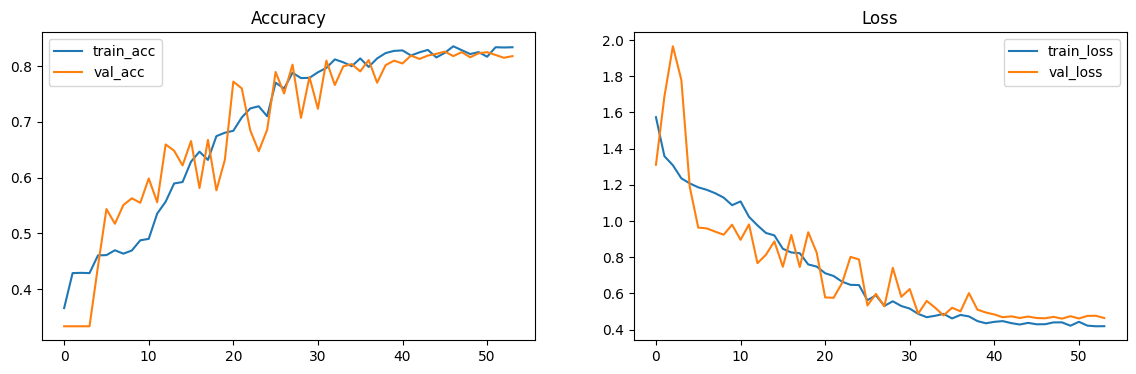

In [ ]:
def plot_history(history):
    h = history.history
    fig, axes = plt.subplots(1,2, figsize=(14,4))
    axes[0].plot(h['sparse_categorical_accuracy'], label='train_acc')
    axes[0].plot(h['val_sparse_categorical_accuracy'], label='val_acc')
    axes[0].set_title('Accuracy')
    axes[0].legend()
    axes[1].plot(h['loss'], label='train_loss')
    axes[1].plot(h['val_loss'], label='val_loss')
    axes[1].set_title('Loss')
    axes[1].legend()
    plt.show()

plot_history(history)

In [ ]:
if os.path.exists(checkpoint_path):
    model.load_weights(checkpoint_path)

TTA (Test-Time Augmentation) — это техника, когда модель делает несколько предсказаний для одного изображения, но на его слегка изменённых версиях.

In [ ]:
def tta_predict_single(model, img_tensor):
    img = tf.expand_dims(img_tensor, axis=0)
    preds = []
    preds.append(model.predict(img, verbose=0)[0])
    preds.append(model.predict(tf.image.flip_left_right(img), verbose=0)[0])
    brighter = tf.clip_by_value(img + 0.03, -1.0, 1.0)
    preds.append(model.predict(brighter, verbose=0)[0])
    contrast = tf.clip_by_value((img - 0.0) * 1.08, -1.0, 1.0)
    preds.append(model.predict(contrast, verbose=0)[0])
    preds = np.stack(preds, axis=0)
    return preds.mean(axis=0)

In [ ]:
def predict_dataset_with_tta(model, ds, use_tta=True):
    y_true = []
    y_pred = []
    probs = []
    for imgs, labs in ds:
        if use_tta:
            for i in range(imgs.shape[0]):
                img = imgs[i]
                p = tta_predict_single(model, img)
                probs.append(p)
                y_pred.append(np.argmax(p))
            y_true.extend(labs.numpy().tolist())
        else:
            p_batch = model.predict(imgs, verbose=0)
            probs.append(p_batch)
            y_pred.extend(np.argmax(p_batch, axis=1).tolist())
            y_true.extend(labs.numpy().tolist())
    if not use_tta:
        probs = np.vstack(probs)
    else:
        probs = np.vstack(probs)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return y_true, y_pred, probs

In [ ]:
y_true_test, y_pred_test, y_probs_test = predict_dataset_with_tta(model, test_ds, use_tta=True)

print("Test accuracy (TTA):", np.mean(y_true_test == y_pred_test))
print("Classification report:\n", classification_report(y_true_test, y_pred_test, target_names=class_names, digits=4))

Test accuracy (TTA): 0.705
Classification report:
               precision    recall  f1-score   support

      Normal     0.9479    0.6642    0.7811       137
    Bleeding     0.6341    0.7429    0.6842        35
    Ischemia     0.3810    0.8571    0.5275        28

    accuracy                         0.7050       200
   macro avg     0.6543    0.7547    0.6643       200
weighted avg     0.8136    0.7050    0.7286       200



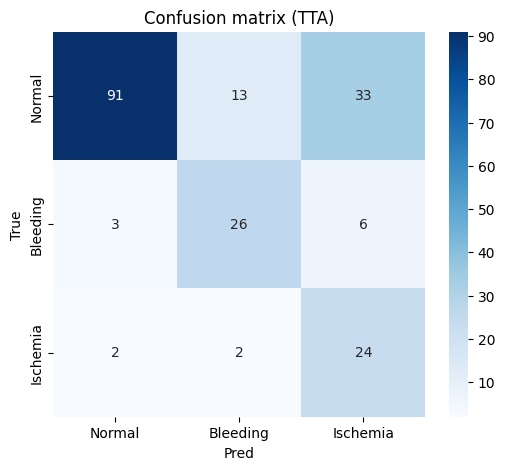

ROC AUC per class: [0.8910902560537597, 0.9241558441558442, 0.8949335548172758]


In [ ]:
cm = confusion_matrix(y_true_test, y_pred_test)
plt.figure(figsize=(6,5)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion matrix (TTA)"); plt.show()

try:
    y_bin = (np.arange(num_class) == y_true_test.reshape(-1,1)).astype(int)
    aucs = [roc_auc_score(y_bin[:, i], y_probs_test[:, i]) for i in range(num_class)]
    print("ROC AUC per class:", aucs)
except Exception as e:
    print("ROC calculation error:", e)

In [ ]:
матрица неточностей
0 91  13  33
1 3   26  6
2 2   2   24
  0   1   2

In [ ]:
def show_test_predictions(model, paths, labels, n=12, use_tta=True):
    plt.figure(figsize=(15, 12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 4
    rows = int(np.ceil(len(idxs)/cols))
    for i, idx in enumerate(idxs):
        path = paths[idx]
        img_raw = tf.io.read_file(path)
        img = safe_decode_png(path)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img = tf.image.resize(img, img_size)
        img_rgb = tf.image.grayscale_to_rgb(img)
        img_norm = img_rgb * 2.0 - 1.0
        if use_tta:
            pred_probs = tta_predict_single(model, img_norm)
        else:
            pred_probs = model.predict(tf.expand_dims(img_norm, axis=0), verbose=0)[0]
        pcls = np.argmax(pred_probs)
        tcls = labels[idx]
        plt.subplot(rows, cols, i+1)
        plt.imshow(tf.squeeze(img) , cmap='gray')
        color = "green" if int(pcls) == int(tcls) else "red"
        fname = os.path.basename(path)
        plt.title(f"{fname}\nT:{class_names[int(tcls)]} P:{class_names[int(pcls)]}\n{pred_probs.round(3)}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


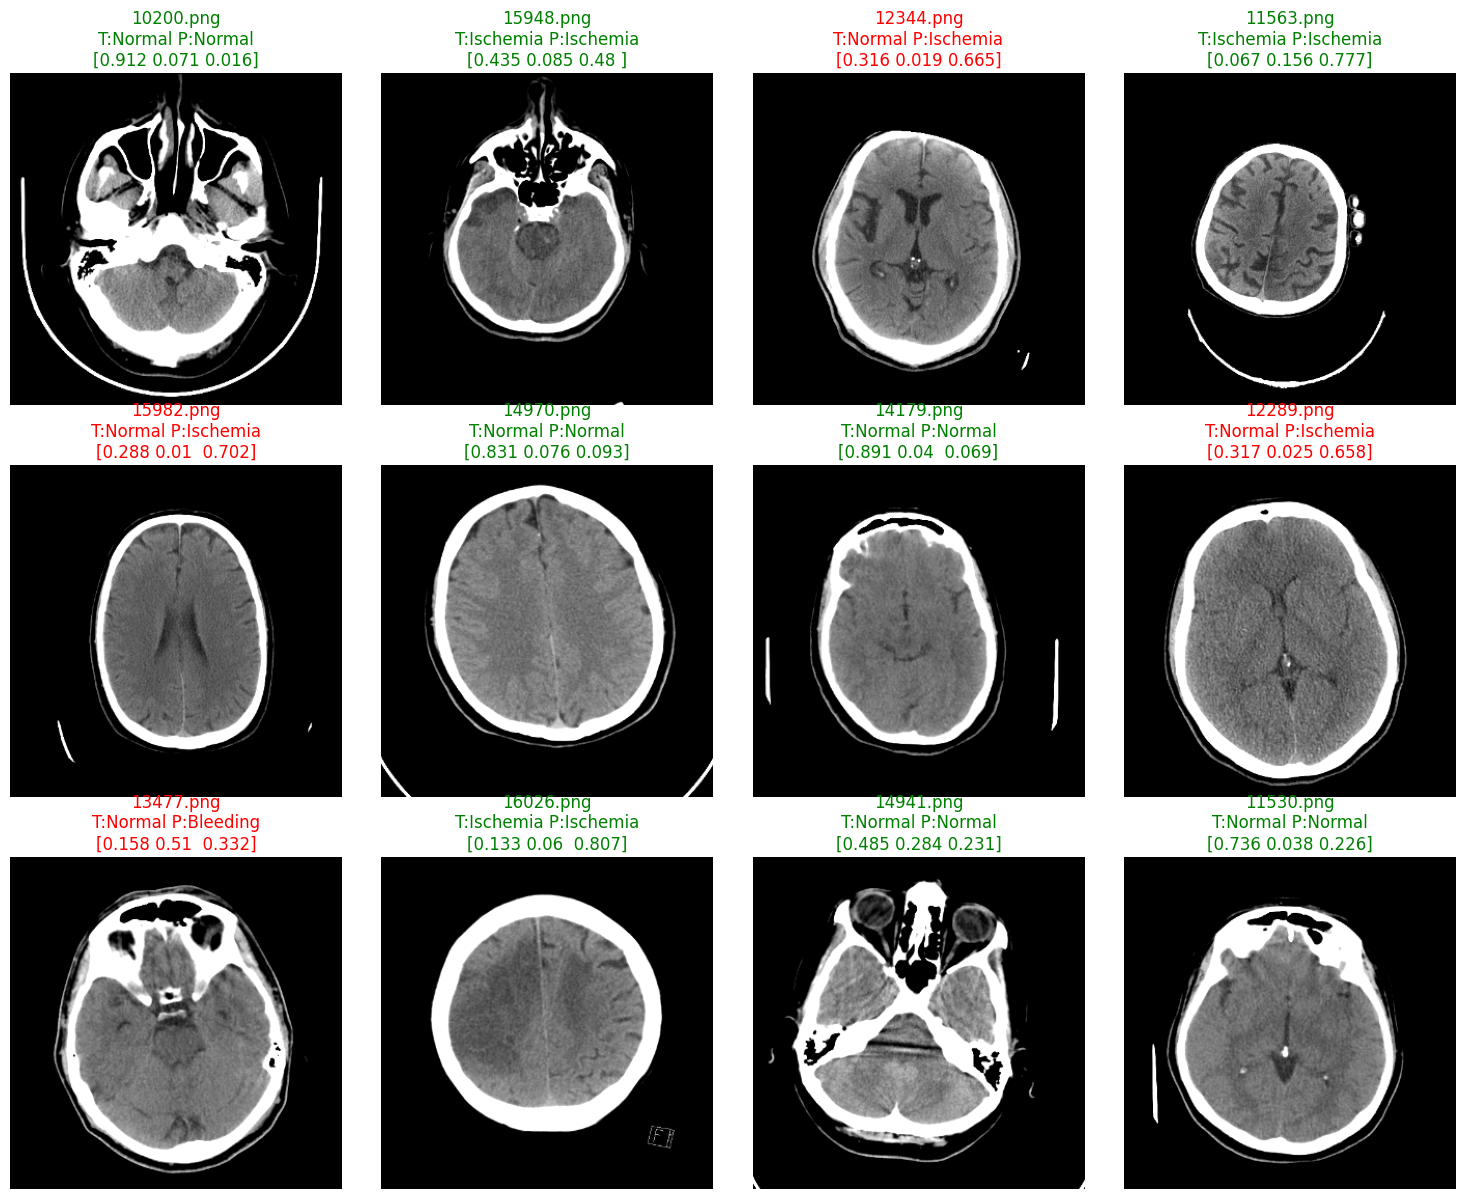

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12, use_tta=True)

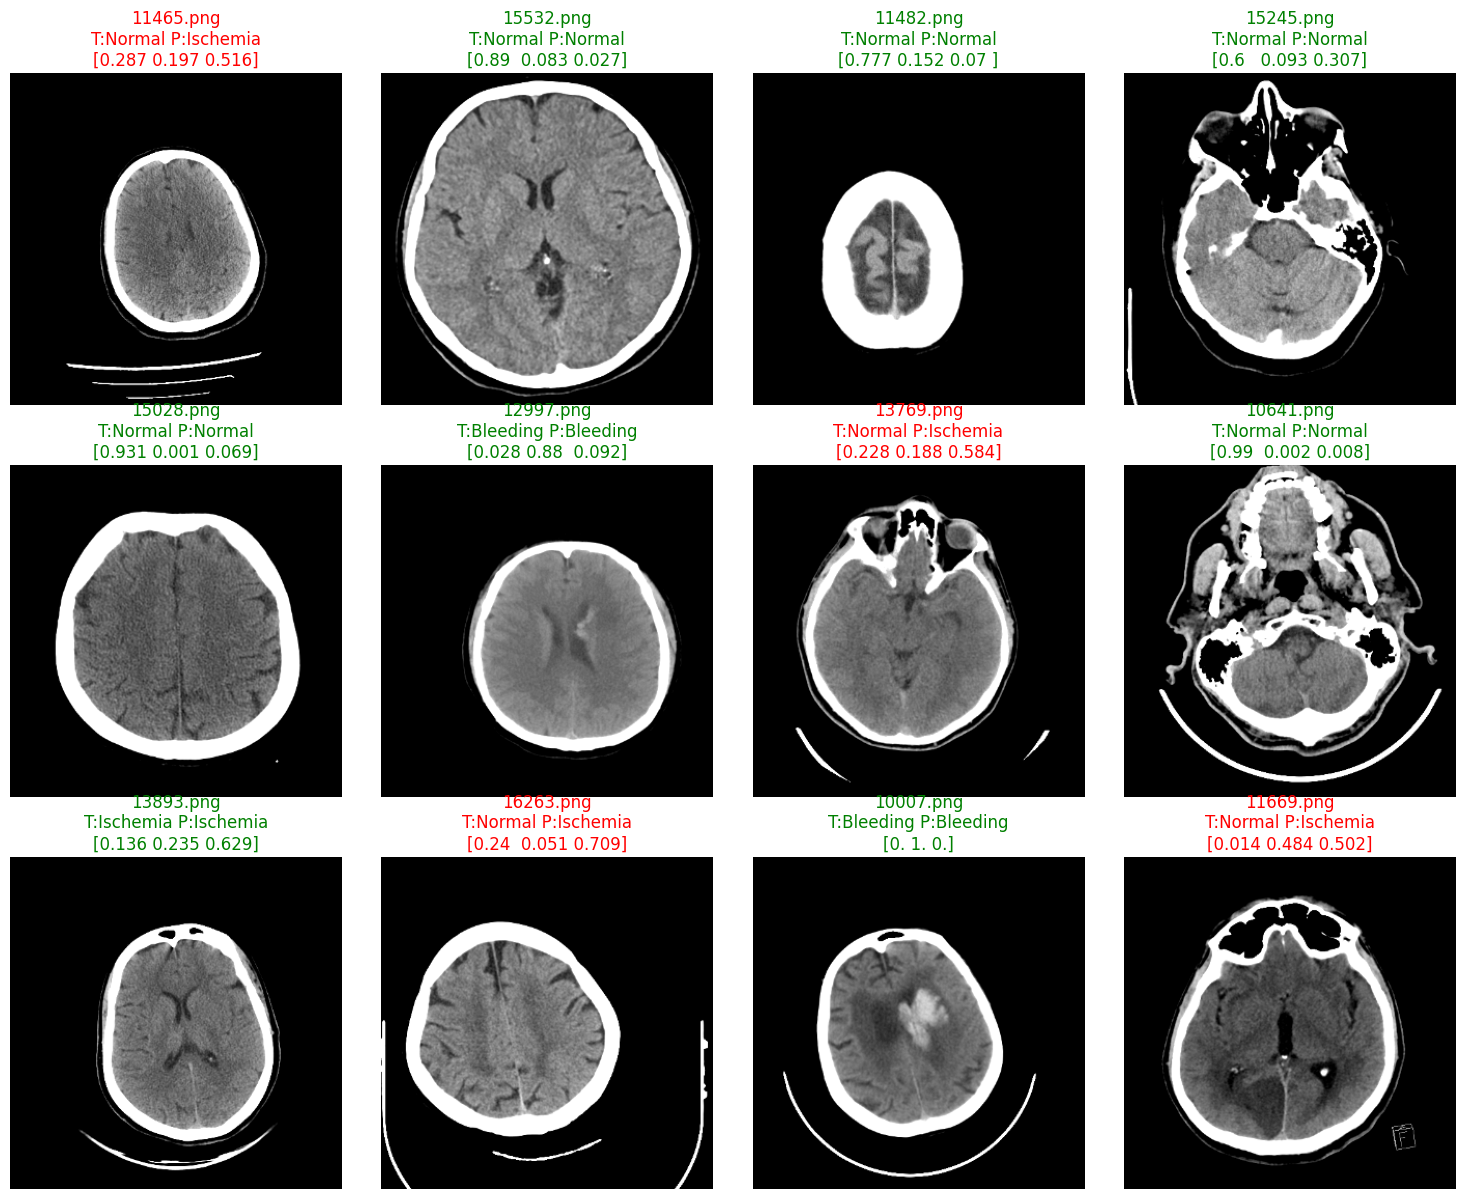

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12, use_tta=True)

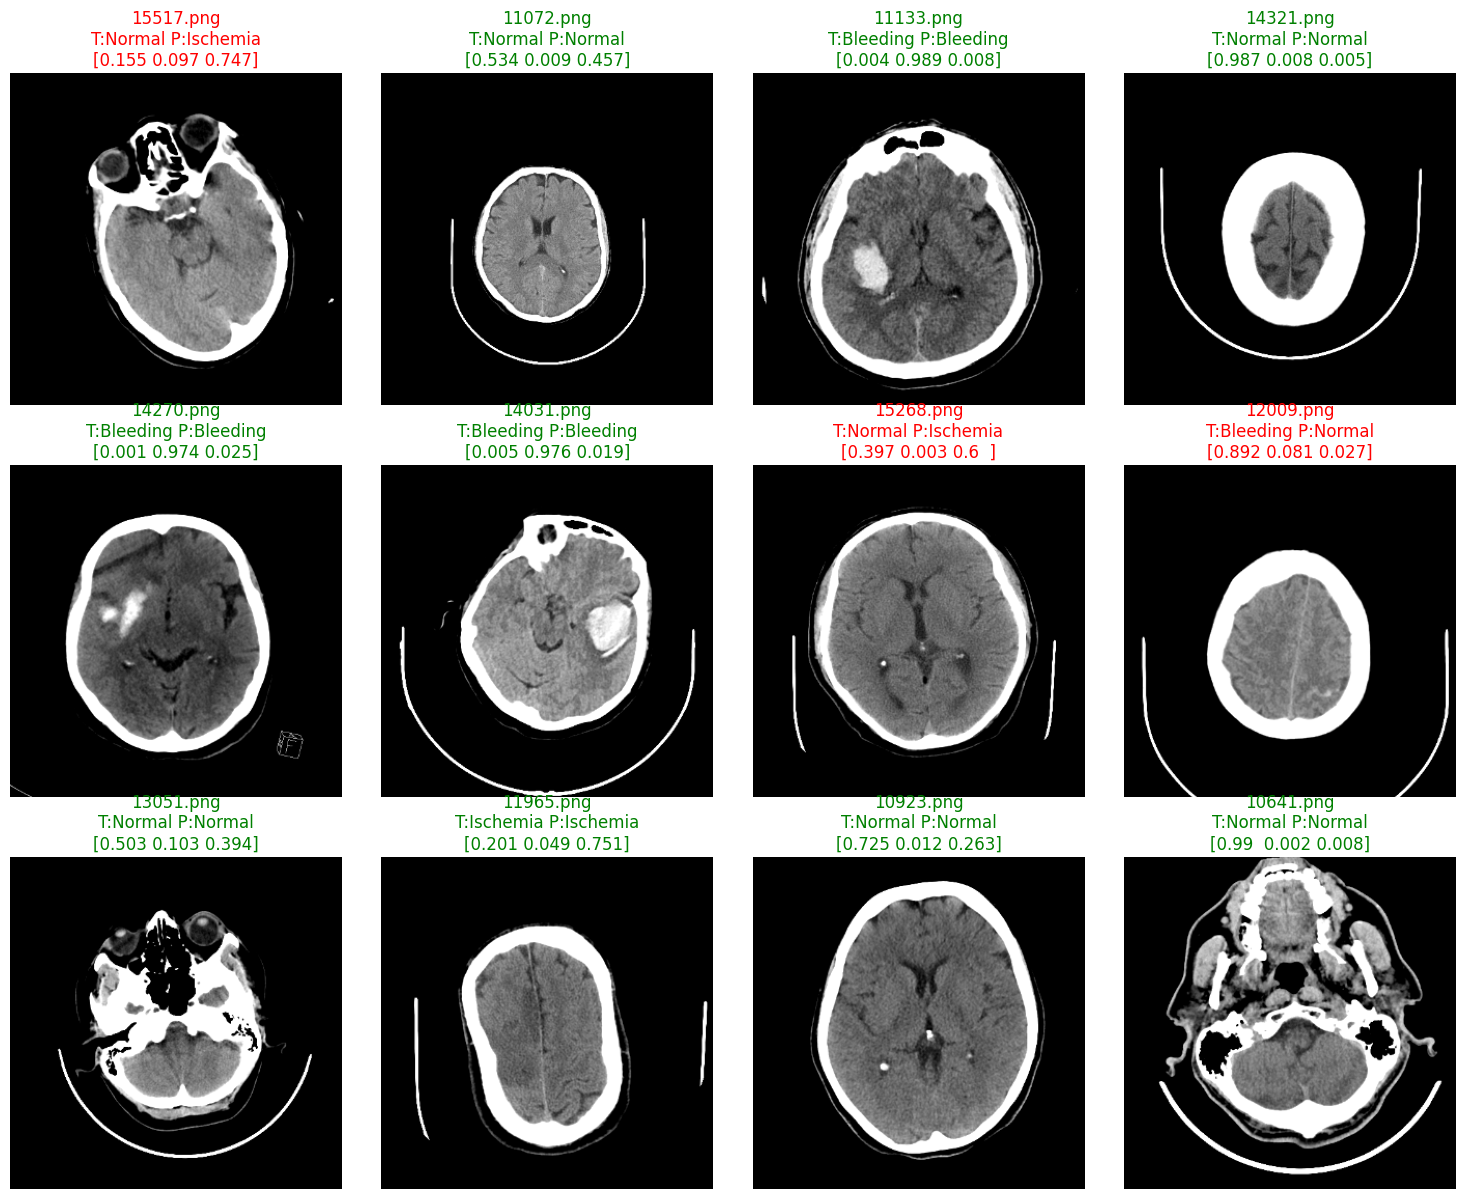

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12, use_tta=True)

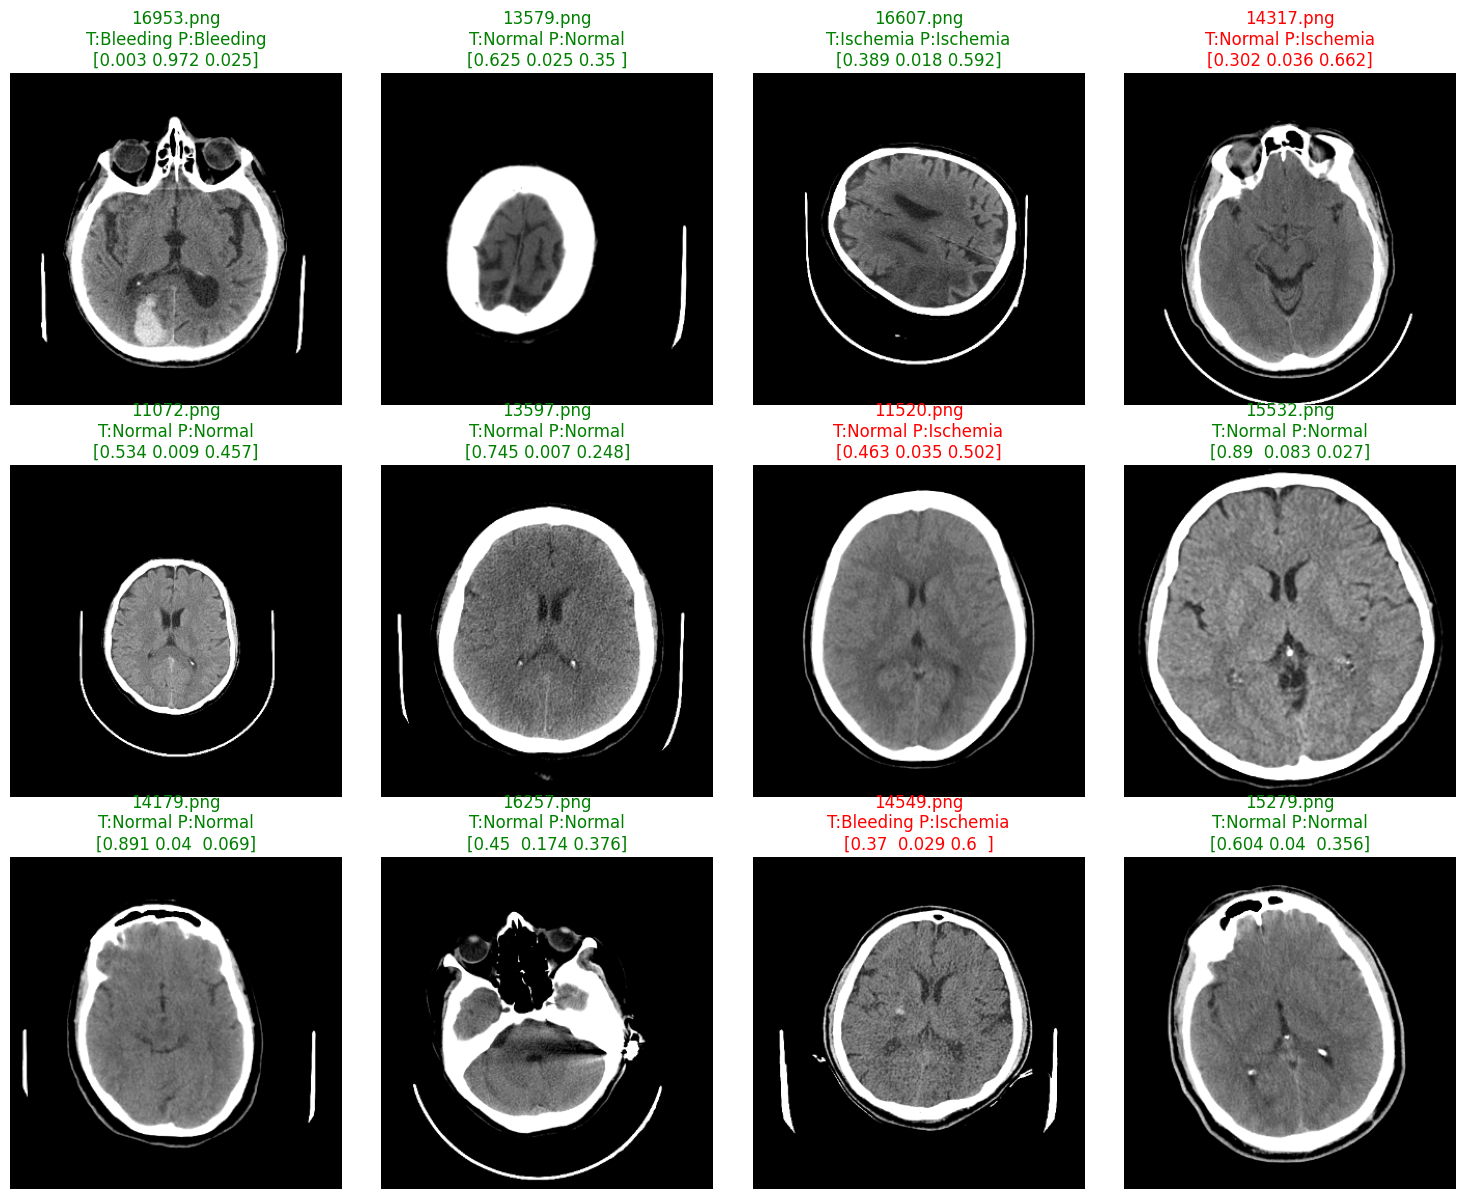

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12, use_tta=True)

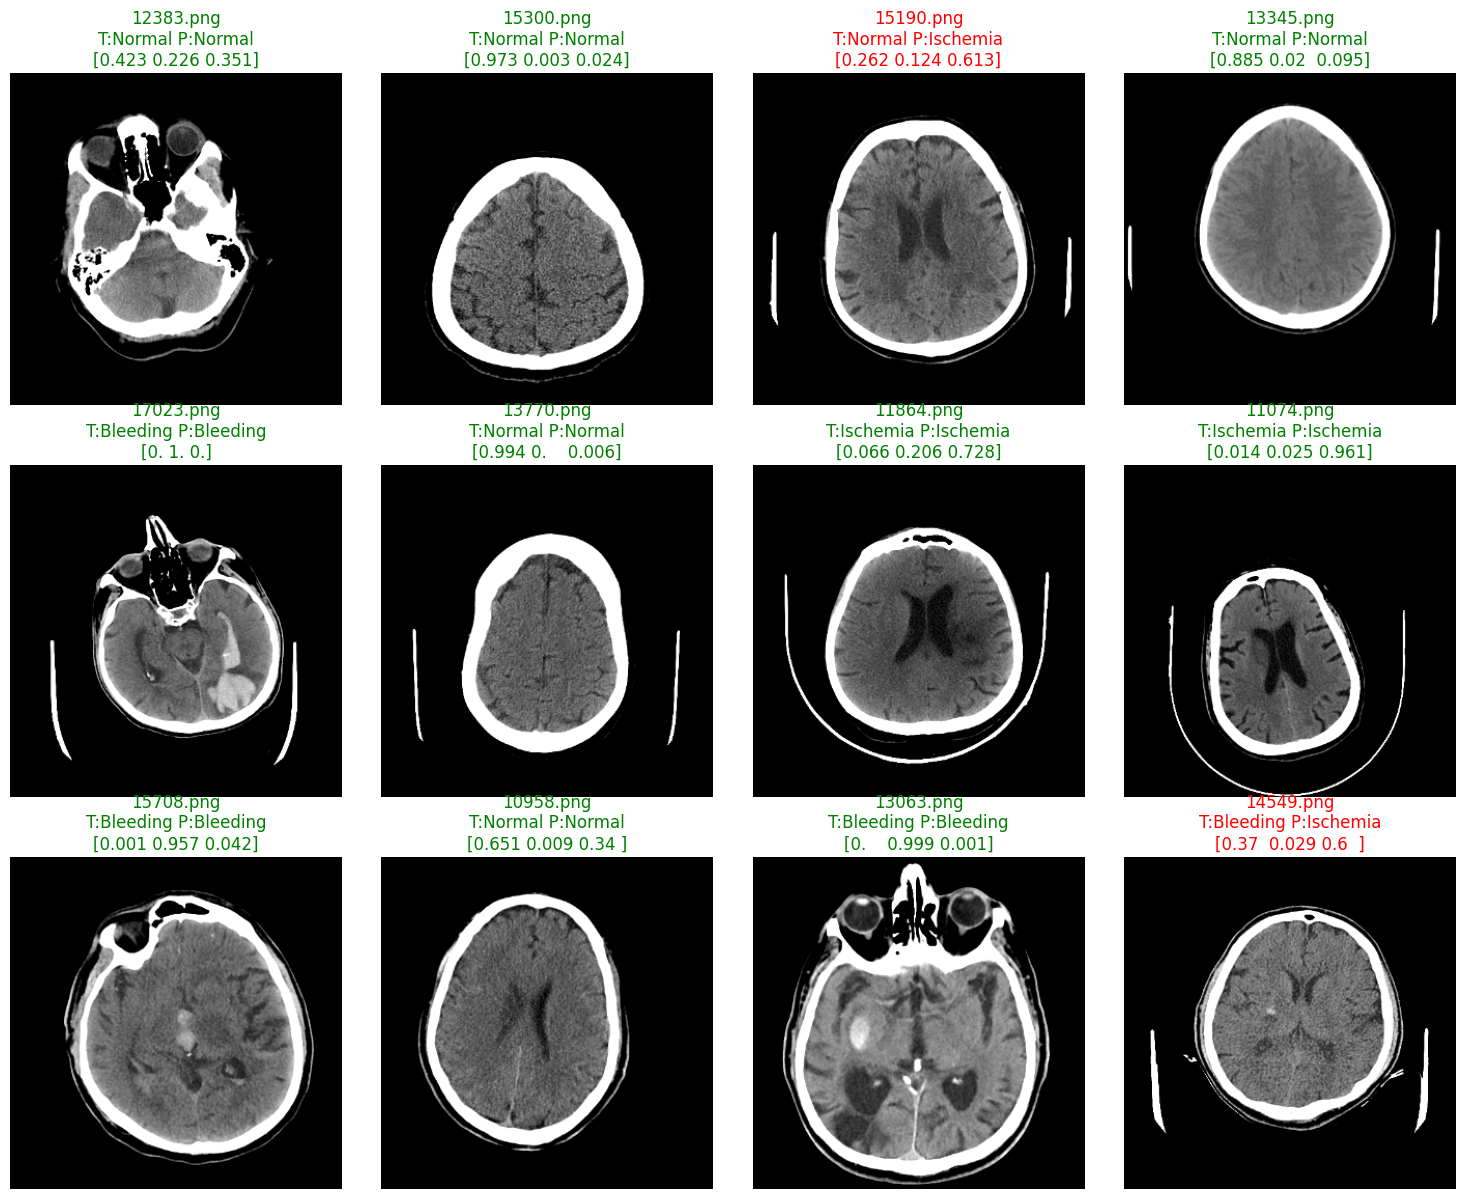

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12, use_tta=True)